# Phase 3: ALE and leakage audit (XGBoost early warning model)

Standalone notebook (does not depend on in-memory objects from `notebooks/PCA_FLEMMS_streamlined.ipynb`).

It does two things:

1. **Addresses three leakage risks** found in the plan review:
   - *Selection leakage*: Phase 1B ranked features by gain on all rows before the 80/20 split. Here the split is made first and feature selection uses **training rows only**.
   - *Household leakage*: members of one household share many features. The split is grouped by `HHID`, so no household appears in both train and test.
   - *Target-proxy features*: `READ_IND_F3` (Form 3 reading indicator) and any other `READ_IND*`, `RESULT_CODE*`, `RESP_AGREE*` fields are excluded in the primary model, and a sensitivity table shows the effect of each exclusion.
2. **Computes Accumulated Local Effects (ALE)** for the top features of the primary model, weighted with `RESP_RFACT_F2`, on the log-odds scale.

Outputs are written next to this notebook in `02_xgboost_xai/`.

In [1]:
import gc, os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
TOP_K = 44            # same size as Phase 1B so results stay comparable
N_TREES_SELECT = 200  # selection model
N_TREES_FINAL = 300   # same hyperparameters as Phase 2

DATA = '../data/PHL-PSA-FLEMMS-2024-V1-PUF/'
DATA2 = '../data/PHL-PSA-FLEMMS-2024-V2-PUF/'
MEMBER_FILE = DATA + 'FLEMMS PUF 2024 Volume1 - MEMBER.CSV'
RTF1_FILE = DATA + 'FLEMMS PUF 2024 Volume1 - RTF1.CSV'
RTF2_FILE = DATA + 'FLEMMS PUF 2024 Volume1 - RTF2.CSV'
RTF3_FILE = DATA2 + 'FLEMMS PUF 2024 Volume2 - RTF3.CSV'
PHASE1B_FILE = '../01b_supervised_selection/phase1b_selected_features.csv'
FIG_DIR = 'ale_figures'
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Load, merge, filter

In [2]:
overlap_cols = ['REG', 'PRV', 'MUN', 'BGY', 'URBANITY', 'REG2']

def drop_overlaps(df, keys):
    return df.drop(columns=[c for c in overlap_cols if c in df.columns and c not in keys])

m = pd.read_csv(MEMBER_FILE)
r1 = drop_overlaps(pd.read_csv(RTF1_FILE), ['HHID'])
r2 = pd.read_csv(RTF2_FILE).rename(columns={'LNO_F2': 'LNO'})
r3 = pd.read_csv(RTF3_FILE).rename(columns={'LNO_F3': 'LNO'})
r2, r3 = drop_overlaps(r2, ['HHID', 'LNO']), drop_overlaps(r3, ['HHID', 'LNO'])

# merge-key uniqueness (Notebook_Verification_TODO item 1)
assert not r1['HHID'].duplicated().any()
assert not r2.duplicated(['HHID', 'LNO']).any()
assert not r3.duplicated(['HHID', 'LNO']).any()

df = (m.merge(r1, on='HHID', how='left')
        .merge(r2, on=['HHID', 'LNO'], how='left')
        .merge(r3, on=['HHID', 'LNO'], how='left'))
assert len(df) == len(m), 'merge fan-out'
df = df[(df['AGE'] >= 10) & (df['AGE'] <= 64)].copy()
del m, r1, r2, r3; gc.collect()

df['FLITERATE'] = pd.to_numeric(df['FLITERATE'], errors='coerce')
df = df[df['FLITERATE'].notna() & df['RESP_RFACT_F2'].notna()].reset_index(drop=True)
y = (df['FLITERATE'] == 2).astype(int).to_numpy()   # 1 = functionally illiterate
w = df['RESP_RFACT_F2'].to_numpy(dtype=float)
groups = df['HHID'].to_numpy()
print('analysis rows:', len(df), '| weighted prevalence:', round(np.average(y, weights=w), 4),
      '| households:', len(np.unique(groups)))

analysis rows: 468643 | weighted prevalence: 0.2921 | households: 163655


## 2. Leakage audit of candidate proxies

`READ_IND_F3` is a Form 3 reading indicator. Its skip logic is unverified (no Form 3 questionnaire in the repo), so we check how it relates to the target before deciding. A near-deterministic relation, or a missingness pattern that follows literacy, indicates a proxy that should not be a predictor.

In [3]:
def wrate(col):
    s = df[col].fillna(-1)
    g = pd.DataFrame({'v': s, 'y': y, 'w': w})
    out = g.groupby('v').apply(lambda d: pd.Series({
        'n': len(d), 'share_rows': len(d) / len(g),
        'weighted_illiteracy_rate': np.average(d['y'], weights=d['w'])}))
    return out

cand = [c for c in df.columns if re.match(r'(READ_IND|RESULT_CODE|RESP_AGREE)', c)]
print('Candidate proxy columns present:', cand)
for c in cand:
    print('\n', c, '(-1 = missing)')
    print(wrate(c).round(3).to_string())

Candidate proxy columns present: ['RESULT_CODE_F2', 'RESP_AGREE_F2', 'READ_IND_F2', 'RESULT_CODE_F3', 'RESP_AGREE_F3', 'READ_IND_F3']

 RESULT_CODE_F2 (-1 = missing)
            n  share_rows  weighted_illiteracy_rate
v                                                  
1.0  468643.0         1.0                     0.292

 RESP_AGREE_F2 (-1 = missing)
            n  share_rows  weighted_illiteracy_rate
v                                                  
1.0  468643.0         1.0                     0.292

 READ_IND_F2 (-1 = missing)
          n  share_rows  weighted_illiteracy_rate
v                                                
1  456828.0       0.975                     0.279
2    9516.0       0.020                     1.000
3    2299.0       0.005                     1.000

 RESULT_CODE_F3 (-1 = missing)
            n  share_rows  weighted_illiteracy_rate
v                                                  
1.0  461519.0       0.985                     0.291
2.0    3265.0       0.00

          n  share_rows  weighted_illiteracy_rate
v                                                
     7124.0       0.015                     0.389
1  450576.0       0.961                     0.279
2    8602.0       0.018                     0.939
3    2139.0       0.005                     0.870
9     202.0       0.000                     0.803


## 3. Preprocess (same rules as Phase 1, plus constant-column drop)

Identifiers, weights and Form 2 outputs are excluded as before. All columns except `AGE` are treated as categorical, missing becomes `Not_Applicable`, columns with more than 50 levels and constant columns are dropped, and the result is one-hot encoded with `drop_first=True`.

In [4]:
BASE_EXCLUDE = [
    'HHID', 'LNO', 'REG', 'PRV', 'MUN', 'BGY', 'URBANITY', 'REG2',
    'PSU', 'PSU_MEM', 'PSU_F1', 'PSU_F2', 'PSU_F3',
    'MEM_RFACT', 'HH_RFACT', 'RESP_RFACT_F2', 'RESP_RFACT_F3',
    'RESULT_CODE_F2', 'RESP_AGREE_F2', 'READ_IND_F2',
    'READING', 'WRITING', 'COMPUTE', 'COMPRE',
    'READING59', 'WRITING59', 'COMPUTE59',
    'LLEVEL59', 'LLEVEL10OVER', 'LLEVEL5OVER', 'FLLEVEL', 'FLLEVEL_0',
    'BASIC_NUM', 'BASIC_LIT', 'BLITERATE', 'BLITERATE_1', 'BLITERATE_2',
    'RESULT_CODE_F3', 'RESP_AGREE_F3',
    'AGE_F2', 'AGE_F3', 'SEX_F2', 'SEX_F3', 'REL_F2', 'REL_F3',
    'HGC_GRADE_F2', 'HGC_GRADE_F3', 'FLITERATE']

feat = df.drop(columns=[c for c in BASE_EXCLUDE if c in df.columns])

def as_cat(s):
    if pd.api.types.is_numeric_dtype(s):
        nn = s.dropna()
        if len(nn) and (nn % 1 == 0).all():
            s = s.astype('Int64')
    return s.astype('string').fillna('Not_Applicable')

keep, dropped_card, dropped_const = [], [], []
for c in feat.columns:
    if c == 'AGE':
        keep.append(c); continue
    nu = feat[c].nunique(dropna=False)
    if nu > 50: dropped_card.append(c)
    elif nu <= 1: dropped_const.append(c)
    else: keep.append(c)
print('dropped (>50 levels):', dropped_card)
print('dropped (constant):', dropped_const)

age = feat['AGE'].fillna(feat['AGE'].median()).astype(float)
cats = pd.DataFrame({c: as_cat(feat[c]) for c in keep if c != 'AGE'})
X = pd.get_dummies(cats, drop_first=True, dtype=np.uint8)
X.insert(0, 'AGE', age.to_numpy())
del feat, cats; gc.collect()
print('encoded matrix:', X.shape)

dropped (>50 levels): ['ETHNICITY', 'HGC_GRADE', 'TVOCCOURSE']
dropped (constant): []


encoded matrix: (468643, 740)


## 4. Grouped split by household, then train-only feature selection

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr_idx, te_idx = next(gss.split(X, y, groups))
Xtr, Xte = X.iloc[tr_idx], X.iloc[te_idx]
ytr, yte, wtr, wte = y[tr_idx], y[te_idx], w[tr_idx], w[te_idx]
assert not set(groups[tr_idx]) & set(groups[te_idx]), 'household in both splits'
print(f'train {len(tr_idx):,} | test {len(te_idx):,} | '
      f'prevalence train {ytr.mean():.3f} test {yte.mean():.3f} (unweighted)')

def make_model(n_trees, yy):
    spw = (yy == 0).sum() / max((yy == 1).sum(), 1)
    return XGBClassifier(n_estimators=n_trees, learning_rate=0.05, max_depth=6,
                         scale_pos_weight=spw, tree_method='hist',
                         random_state=SEED, eval_metric='auc', n_jobs=-1)

def select_top(cols, k=TOP_K):
    mdl = make_model(N_TREES_SELECT, ytr)
    mdl.fit(Xtr[cols], ytr, sample_weight=wtr)        # TRAIN rows only
    imp = pd.Series(mdl.feature_importances_, index=cols).sort_values(ascending=False)
    return imp.head(k)

def evaluate(mdl, cols):
    p = mdl.predict_proba(Xte[cols])[:, 1]
    return {'roc_auc_weighted': roc_auc_score(yte, p, sample_weight=wte),
            'pr_auc_weighted': average_precision_score(yte, p, sample_weight=wte),
            'roc_auc_unweighted': roc_auc_score(yte, p)}

def fit_eval(cols, label):
    mdl = make_model(N_TREES_FINAL, ytr)
    mdl.fit(Xtr[cols], ytr, sample_weight=wtr)
    r = {'scenario': label, 'n_features': len(cols), **evaluate(mdl, cols)}
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})
    return mdl, r

all_cols = list(X.columns)
is_f3_reading = lambda c: c.startswith('READ_IND_F3_')
is_tvoc = lambda c: c.startswith('TVOC')

train 374,921 | test 93,722 | prevalence train 0.306 test 0.303 (unweighted)


## 5. Scenario comparison

| Scenario | What it tests |
|---|---|
| S0 | Original Phase 1B list (selected on all rows) evaluated on the grouped test set |
| S1 | Selection on training rows only, baseline exclusions |
| S2 | S1 plus `READ_IND_F3` removed before selection |
| S2b | S2 plus `AGE` forced in as a demographic control (**model used for ALE**) |
| S3 | S2 plus the `TVOC*` family removed (sensitivity) |

In [6]:
rows, models, sel = [], {}, {}

p1b = pd.read_csv(PHASE1B_FILE)['Feature_Name'].tolist()
s0 = [c for c in p1b if c in X.columns]
print(f'S0: {len(s0)} of {len(p1b)} Phase 1B features found in the encoded matrix')
models['S0'], r = fit_eval(s0, 'S0 Phase 1B list (all-rows selection), grouped test'); rows.append(r); sel['S0'] = s0

imp1 = select_top(all_cols);                       sel['S1'] = list(imp1.index)
models['S1'], r = fit_eval(sel['S1'], 'S1 train-only selection'); rows.append(r)

cols2 = [c for c in all_cols if not is_f3_reading(c)]
imp2 = select_top(cols2);                          sel['S2'] = list(imp2.index)
models['S2'], r = fit_eval(sel['S2'], 'S2 train-only, READ_IND_F3 excluded (primary)'); rows.append(r)

cols3 = [c for c in cols2 if not is_tvoc(c)]
imp3 = select_top(cols3);                          sel['S3'] = list(imp3.index)
models['S3'], r = fit_eval(sel['S3'], 'S3 S2 plus TVOC* excluded'); rows.append(r)

# S2b: S2 plus AGE as an a priori demographic control (AGE is not leaky, and the
# U-shaped age profile found in the EDA needs a continuous ALE curve).
imp2b = imp2.copy()
if 'AGE' not in sel['S2']:
    sel['S2b'] = sel['S2'] + ['AGE']
else:
    sel['S2b'] = list(sel['S2'])
print('AGE selected by gain in S2:', 'AGE' in sel['S2'])
models['S2b'], r = fit_eval(sel['S2b'], 'S2b S2 plus AGE forced (ALE model)'); rows.append(r)

scen = pd.DataFrame(rows)
scen.to_csv('leakage_audit_scenarios.csv', index=False)
scen.round(4)

S0: 43 of 44 Phase 1B features found in the encoded matrix


{'scenario': 'S0 Phase 1B list (all-rows selection), grouped test', 'n_features': 43, 'roc_auc_weighted': 0.7005, 'pr_auc_weighted': 0.5155, 'roc_auc_unweighted': 0.7068}


{'scenario': 'S1 train-only selection', 'n_features': 44, 'roc_auc_weighted': 0.6996, 'pr_auc_weighted': 0.516, 'roc_auc_unweighted': 0.7083}


{'scenario': 'S2 train-only, READ_IND_F3 excluded (primary)', 'n_features': 44, 'roc_auc_weighted': 0.701, 'pr_auc_weighted': 0.5042, 'roc_auc_unweighted': 0.7074}


{'scenario': 'S3 S2 plus TVOC* excluded', 'n_features': 44, 'roc_auc_weighted': 0.7004, 'pr_auc_weighted': 0.5038, 'roc_auc_unweighted': 0.7067}
AGE selected by gain in S2: False


{'scenario': 'S2b S2 plus AGE forced (ALE model)', 'n_features': 45, 'roc_auc_weighted': 0.7019, 'pr_auc_weighted': 0.5051, 'roc_auc_unweighted': 0.7082}


,scenario,n_features,roc_auc_weighted,pr_auc_weighted,roc_auc_unweighted
0,"S0 Phase 1B list (all-rows selection), grouped...",43,0.7005,0.5155,0.7068
1,S1 train-only selection,44,0.6996,0.5160,0.7083
2,"S2 train-only, READ_IND_F3 excluded (primary)",44,0.7010,0.5042,0.7074
3,S3 S2 plus TVOC* excluded,44,0.7004,0.5038,0.7067
4,S2b S2 plus AGE forced (ALE model),45,0.7019,0.5051,0.7082


In [7]:
def overlap(a, b): return len(set(a) & set(b))
print('S1 vs S0 overlap:', overlap(sel['S1'], sel['S0']), 'of', TOP_K)
print('S2 vs S1 overlap:', overlap(sel['S2'], sel['S1']), 'of', TOP_K)
print('S3 vs S2 overlap:', overlap(sel['S3'], sel['S2']), 'of', TOP_K)
print('READ_IND_F3 columns in S1:', [c for c in sel['S1'] if is_f3_reading(c)])
print('TVOC columns in S2:', [c for c in sel['S2'] if is_tvoc(c)])

names = pd.read_csv(PHASE1B_FILE).set_index('Feature_Name')['Descriptive_Name'].to_dict()
sel_df = pd.DataFrame({'Feature_Name': sel['S2'], 'Train_Gain': imp2.values})
sel_df['Forced_In'] = False
if 'AGE' not in sel['S2']:
    sel_df = pd.concat([sel_df, pd.DataFrame([{'Feature_Name': 'AGE', 'Train_Gain': np.nan, 'Forced_In': True}])], ignore_index=True)
sel_df['Descriptive_Name'] = sel_df['Feature_Name'].map(names).fillna(sel_df['Feature_Name'])
sel_df['In_Original_Phase1B'] = sel_df['Feature_Name'].isin(p1b)
sel_df.to_csv('selected_features_train_only.csv', index=False)
sel_df.head(15)

S1 vs S0 overlap: 36 of 44
S2 vs S1 overlap: 32 of 44
S3 vs S2 overlap: 33 of 44
READ_IND_F3 columns in S1: ['READ_IND_F3_2', 'READ_IND_F3_1', 'READ_IND_F3_3']
TVOC columns in S2: ['TVOCTRAIN_5', 'TVOCGRAD_5', 'TVOCAT_1']


,Feature_Name,Train_Gain,Forced_In,Descriptive_Name,In_Original_Phase1B
0,TVOCTRAIN_5,0.096190,False,Attending Technical Vocational Training: No,True
1,HGC_LEVEL_1,0.072322,False,Highest HGC_GRADE completed: Primary Education...,True
2,DSKILL_PROB6_1,0.032764,False,Digital Skill: Problem solving: YES,True
3,DSKILL_INFO2_1,0.026988,False,Digital Skill: Information and data literacy: YES,True
4,INTERNET_1,0.020700,False,Have you Used Internet in the past three (3) m...,True
5,TVOCGRAD_5,0.016066,False,Are you a graduate of TechVoc: No,True
6,HGC_LEVEL_6,0.012970,False,Highest HGC_GRADE completed: Bachelor Level Ed...,True
7,MM_WORK_1,0.012463,False,Mass Media: Research Work or E-mail: Not at al...,True
8,DSKILL_CONT1_1,0.012450,False,Digital Skill: Digital content creation: YES,True
9,DSKILL_SAFE2_1,0.011894,False,Digital Skill: Safety: YES,True


## 6. Primary model (S2b): metrics

Weighted ROC-AUC and PR-AUC on the household-grouped held-out set.

In [8]:
final_cols = sel['S2b']
model = models['S2b']
res = evaluate(model, final_cols)
res_df = pd.DataFrame([res])
res_df.to_csv('primary_model_metrics.csv', index=False)
print(res_df.round(4).to_string(index=False))

pte = model.predict_proba(Xte[final_cols])[:, 1]
from sklearn.metrics import classification_report
print(classification_report(yte, (pte >= 0.5).astype(int), sample_weight=wte, digits=3))

 roc_auc_weighted  pr_auc_weighted  roc_auc_unweighted
           0.7019           0.5051              0.7082


              precision    recall  f1-score   support

           0      0.808     0.696     0.748 12171168.785333455
           1      0.443     0.593     0.508 4965744.813687202

    accuracy                          0.666 17136913.599020656
   macro avg      0.625     0.645     0.628 17136913.599020656
weighted avg      0.702     0.666     0.678 17136913.599020656



## 7. Accumulated Local Effects

ALE is computed on the model's **log-odds (margin)** output so effects are additive. `scale_pos_weight` shifts the intercept but not the shape of the curves. For each feature:

- Continuous (`AGE`): 20 quantile bins; the local effect is the mean change in log-odds when the value moves from the lower to the upper bin edge, accumulated across bins and centred at the weighted mean.
- Binary dummy: the effect of switching the dummy from 0 to 1 evaluated on rows where it equals 1 (the realistic local neighbourhood), centred on the weighted mean.

All averages use `RESP_RFACT_F2`. The test set is used so the curves describe held-out data.

In [9]:
def margin(mdl, frame, cols):
    return mdl.predict(frame[cols], output_margin=True)

def ale_continuous(mdl, frame, wts, cols, f, K=20):
    x = frame[f].to_numpy(dtype=float)
    edges = np.unique(np.quantile(x, np.linspace(0, 1, K + 1)))
    idx = np.clip(np.searchsorted(edges, x, side='left') - 1, 0, len(edges) - 2)
    lo, hi = frame[cols].copy(), frame[cols].copy()
    lo[f] = edges[idx]; hi[f] = edges[idx + 1]
    d = margin(mdl, hi, cols) - margin(mdl, lo, cols)
    nb = len(edges) - 1
    sw = np.bincount(idx, weights=wts, minlength=nb)
    mean_d = np.bincount(idx, weights=wts * d, minlength=nb) / np.maximum(sw, 1e-12)
    ale = np.concatenate([[0.0], np.cumsum(mean_d)])           # value at each edge
    centre = np.sum(sw * (ale[1:] + ale[:-1]) / 2) / sw.sum()   # weighted mean over bins
    return pd.DataFrame({'x': edges, 'ale': ale - centre})

def ale_binary(mdl, frame, wts, cols, f):
    on = frame[f].to_numpy() == 1
    lo, hi = frame.loc[on, cols].copy(), frame.loc[on, cols].copy()
    lo[f] = 0; hi[f] = 1
    d = margin(mdl, hi, cols) - margin(mdl, lo, cols)
    delta = np.average(d, weights=wts[on])
    p1 = wts[on].sum() / wts.sum()
    return pd.DataFrame({'x': [0, 1], 'ale': [-p1 * delta, (1 - p1) * delta]}), delta, p1

# Rank features of the primary model by gain, always include AGE
imp_final = pd.Series(model.feature_importances_, index=final_cols).sort_values(ascending=False)
plot_feats = list(imp_final.head(12).index)
if 'AGE' in final_cols and 'AGE' not in plot_feats:
    plot_feats.append('AGE')

Xs = Xte[final_cols]
records, summary = [], []
for f in plot_feats:
    if f == 'AGE':
        a = ale_continuous(model, Xs, wte, final_cols, f)
        a['Feature'] = f; records.append(a)
        summary.append({'Feature': f, 'Type': 'continuous', 'Gain': imp_final[f],
                        'ALE_range_logodds': a['ale'].max() - a['ale'].min(),
                        'Effect_0_to_1_logodds': np.nan, 'Odds_ratio_0_to_1': np.nan,
                        'Share_rows_on': np.nan})
    else:
        a, delta, p1 = ale_binary(model, Xs, wte, final_cols, f)
        a['Feature'] = f; records.append(a)
        summary.append({'Feature': f, 'Type': 'binary', 'Gain': imp_final[f],
                        'ALE_range_logodds': abs(delta),
                        'Effect_0_to_1_logodds': delta, 'Odds_ratio_0_to_1': float(np.exp(delta)),
                        'Share_rows_on': p1})

ale_vals = pd.concat(records, ignore_index=True)[['Feature', 'x', 'ale']]
ale_sum = pd.DataFrame(summary)
ale_sum['Descriptive_Name'] = ale_sum['Feature'].map(names).fillna(ale_sum['Feature'])
ale_sum['Direction'] = np.where(ale_sum['Effect_0_to_1_logodds'].fillna(0) > 0, 'Increases Risk',
                         np.where(ale_sum['Effect_0_to_1_logodds'].isna(), 'See curve', 'Decreases Risk'))
ale_vals.to_csv('ale_values.csv', index=False)
ale_sum.to_csv('ale_effect_summary.csv', index=False)
ale_sum.round(3)

,Feature,Type,Gain,ALE_range_logodds,Effect_0_to_1_logodds,Odds_ratio_0_to_1,Share_rows_on,Descriptive_Name,Direction
0,HGC_LEVEL_1,binary,0.252,0.652,-0.652,0.521,0.224,Highest HGC_GRADE completed: Primary Education...,Decreases Risk
1,TVOCTRAIN_5,binary,0.197,0.131,-0.131,0.877,0.295,Attending Technical Vocational Training: No,Decreases Risk
2,TVOCGRAD_5,binary,0.041,0.142,-0.142,0.867,0.283,Are you a graduate of TechVoc: No,Decreases Risk
3,INTERNET_1,binary,0.040,0.106,-0.106,0.900,0.765,Have you Used Internet in the past three (3) m...,Decreases Risk
4,DSKILL_INFO2_1,binary,0.040,0.091,-0.091,0.913,0.504,Digital Skill: Information and data literacy: YES,Decreases Risk
5,DSKILL_PROB6_1,binary,0.034,0.089,-0.089,0.915,0.418,Digital Skill: Problem solving: YES,Decreases Risk
6,HGC_LEVEL_6,binary,0.027,0.097,-0.097,0.908,0.260,Highest HGC_GRADE completed: Bachelor Level Ed...,Decreases Risk
7,HGC_LEVEL_2,binary,0.026,0.687,-0.687,0.503,0.379,Highest HGC_GRADE completed: Lower Secondary E...,Decreases Risk
8,MM_WORK_1,binary,0.020,0.158,0.158,1.171,0.433,Mass Media: Research Work or E-mail: Not at al...,Increases Risk
9,DSKILL_CONT1_1,binary,0.018,0.066,-0.066,0.936,0.260,Digital Skill: Digital content creation: YES,Decreases Risk


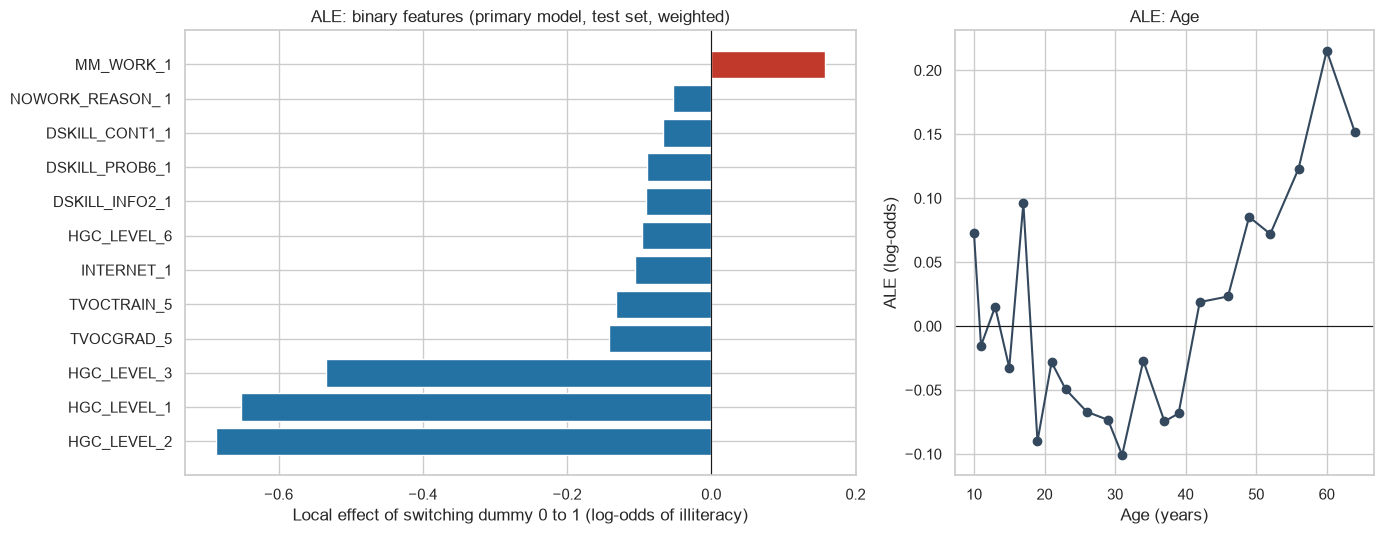

In [10]:
bins = [f for f in plot_feats if f != 'AGE']
n = len(plot_feats) + 0
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.6, 1]})

# Left: binary dummies, effect of switching 0 -> 1
b = ale_sum[ale_sum['Type'] == 'binary'].sort_values('Effect_0_to_1_logodds')
cols_ = ['#c0392b' if v > 0 else '#2471a3' for v in b['Effect_0_to_1_logodds']]
axes[0].barh(b['Feature'], b['Effect_0_to_1_logodds'], color=cols_)
axes[0].axvline(0, color='k', lw=0.8)
axes[0].set_xlabel('Local effect of switching dummy 0 to 1 (log-odds of illiteracy)')
axes[0].set_title('ALE: binary features (primary model, test set, weighted)')

# Right: AGE curve
if 'AGE' in plot_feats:
    a = ale_vals[ale_vals['Feature'] == 'AGE']
    axes[1].plot(a['x'], a['ale'], marker='o', color='#34495e')
    axes[1].axhline(0, color='k', lw=0.8)
    axes[1].set_xlabel('Age (years)'); axes[1].set_ylabel('ALE (log-odds)')
    axes[1].set_title('ALE: Age')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'ale_primary_model.png'), dpi=200, bbox_inches='tight')
plt.show()

## 8. Stability check

ALE for the leading features recomputed on two random halves of the test households. Large disagreement would mean the curves are not reliable.

In [11]:
rng = np.random.RandomState(SEED)
hh = np.unique(groups[te_idx]); rng.shuffle(hh)
half_a = np.isin(groups[te_idx], hh[: len(hh) // 2])
rows = []
for f in [p for p in plot_feats if p != 'AGE'][:8]:
    ds = []
    for msk in (half_a, ~half_a):
        _, delta, _ = ale_binary(model, Xs[msk], wte[msk], final_cols, f)
        ds.append(delta)
    rows.append({'Feature': f, 'Effect_half_A': ds[0], 'Effect_half_B': ds[1],
                 'Abs_diff': abs(ds[0] - ds[1])})
stab = pd.DataFrame(rows)
stab.to_csv('ale_stability_halves.csv', index=False)
stab.round(3)

,Feature,Effect_half_A,Effect_half_B,Abs_diff
0,HGC_LEVEL_1,-0.649,-0.655,0.006
1,TVOCTRAIN_5,-0.132,-0.131,0.002
2,TVOCGRAD_5,-0.143,-0.142,0.001
3,INTERNET_1,-0.106,-0.106,0.000
4,DSKILL_INFO2_1,-0.092,-0.090,0.001
5,DSKILL_PROB6_1,-0.089,-0.088,0.001
6,HGC_LEVEL_6,-0.098,-0.095,0.004
7,HGC_LEVEL_2,-0.682,-0.692,0.011
